In [8]:
import time
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'models' / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras

from common import contract, data, metrics, paths, plots
import mlp

plots.aplicar_estilo()

SEMENTE = contract.SEED
FEATURES = mlp.ENTRADAS

OCULTAS = (256, 128, 64)

# Valores por granularidade. A granularidade e' detectada do intervalo mediano do
# split de treino; 1d/1h/5min usam batches e taxas diferentes.
HIPERPARAMETROS = {
    "1d":   dict(EPOCHS=500, BATCH=32,  PACIENCIA=60, LR=1e-3),
    "1h":   dict(EPOCHS=300, BATCH=64,  PACIENCIA=40, LR=5e-4),
    "5min": dict(EPOCHS=200, BATCH=128, PACIENCIA=25, LR=3e-4),
}
# Huber delta nao e' parametro de granularidade: e' limiar na escala do residuo.
HUBER_DELTA_FRAC = 0.25

_passo = data.load_split("train")["datetime"].sort_values().diff().median()
if _passo <= pd.Timedelta(minutes=5):
    GRANULARIDADE = "5min"
elif _passo <= pd.Timedelta(hours=1):
    GRANULARIDADE = "1h"
else:
    GRANULARIDADE = "1d"
_cfg = HIPERPARAMETROS[GRANULARIDADE]
EPOCHS, BATCH, PACIENCIA, LR = (
    _cfg["EPOCHS"], _cfg["BATCH"], _cfg["PACIENCIA"], _cfg["LR"])

keras.utils.set_random_seed(SEMENTE)
np.random.seed(SEMENTE)

print("tensorflow", tf.__version__, "| keras", keras.__version__)
print(f"entradas: {len(FEATURES)} -> {', '.join(FEATURES)}")
print(f"granularidade: {GRANULARIDADE} | EPOCHS={EPOCHS} BATCH={BATCH} "
      f"PACIENCIA={PACIENCIA} LR={LR:g}")


tensorflow 2.21.0 | keras 3.15.1
entradas: 3 -> temperatura_ambiente, ghit, jacques
granularidade: 1h | EPOCHS=300 BATCH=64 PACIENCIA=40 LR=0.0005


In [9]:
dados, _, _ = mlp.prepara()

X_tre, y_tre = dados["treino"]["X"], dados["treino"]["y"]
X_val, y_val = dados["validacao"]["X"], dados["validacao"]["y"]
X_tes, y_tes = dados["teste"]["X"], dados["teste"]["y"]

HUBER_DELTA = HUBER_DELTA_FRAC * float(
    np.quantile(y_tre, .75) - np.quantile(y_tre, .25))

for nome, X, y in (("treino", X_tre, y_tre), ("validacao", X_val, y_val),
                   ("teste", X_tes, y_tes)):
    print(f"{nome:10} {len(X):6} amostras de {X.shape[1]:2} entradas | "
          f"PCA {y.min():.2f}..{y.max():.2f} kW | media {y.mean():.3f}")

PCA_MIN, PCA_MAX = data.target_limits()

for nome, y in (("treino", y_tre), ("validacao", y_val), ("teste", y_tes)):
    fora = int(((y < PCA_MIN) | (y > PCA_MAX)).sum())
    if fora:
        print(f"ATENCAO: {nome}: {fora}/{len(y)} alvos fora de "
              f"[{PCA_MIN}, {PCA_MAX}] kW - contrato/dataset_prep divergem")

assert len(X_tes) > 100, f"teste ficou com so {len(X_tes)} amostras"
assert X_tre.dtype == np.float32 and X_tes.dtype == np.float32
print("OK: X em [0, 1] (min-max ajustado so no treino)")
print(f"HUBER_DELTA = {HUBER_DELTA:.3f} kW (0.25 x IQR do treino)")


treino      10508 amostras de  3 entradas | PCA 0.00..22.95 kW | media 9.892
validacao    5658 amostras de  3 entradas | PCA 0.00..22.98 kW | media 9.871
teste        4042 amostras de  3 entradas | PCA 0.00..22.19 kW | media 9.829
OK: X em [0, 1] (min-max ajustado so no treino)
HUBER_DELTA = 2.402 kW (0.25 x IQR do treino)


In [10]:
camadas = [keras.layers.Input(shape=(len(FEATURES),), name="features")]
for i, n in enumerate(OCULTAS):
    camadas.append(keras.layers.Dense(n, activation="relu", name=f"oculta_{i}"))
media_y = float(y_tre.mean())
camadas.append(keras.layers.Dense(
    1, name="pca_kw",
    bias_initializer=keras.initializers.Constant(media_y)))

modelo = keras.Sequential(camadas, name="knob_senses_pca")
modelo.compile(
    optimizer=keras.optimizers.Adam(LR),
    loss=keras.losses.Huber(delta=HUBER_DELTA),
    metrics=[keras.metrics.RootMeanSquaredError(name="rmse"), "mae"],
)
modelo.summary()


Model: "knob_senses_pca"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_0 (Dense)                │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pca_kw (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,241 (165.00 KB)

 Trainable params: 42,241 (165.00 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
chamadas = [
    keras.callbacks.EarlyStopping(monitor="val_mae", patience=PACIENCIA,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5, patience=8,
                                      min_lr=1e-5, verbose=1),
]

t0 = time.perf_counter()
historico = modelo.fit(
    X_tre, y_tre,
    validation_data=(X_val, y_val),
    epochs=EPOCHS, batch_size=BATCH, callbacks=chamadas, verbose=0,
)
print(f"treino da rede: {time.perf_counter() - t0:.1f} s")
print(f"parou na epoca {len(historico.history['loss'])} "
      f"(melhor val_mae {min(historico.history['val_mae']):.5f})")



Epoch 18: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 149: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 157: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 169: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 186: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.

Epoch 194: ReduceLROnPlateau reducing learning rate to 1e-05.
Epoch 226: early stopping
Restoring model weights from the end of the best epoch: 186.
treino da rede: 88.5 s
parou na epoca 226 (melhor val_mae 0.64174)


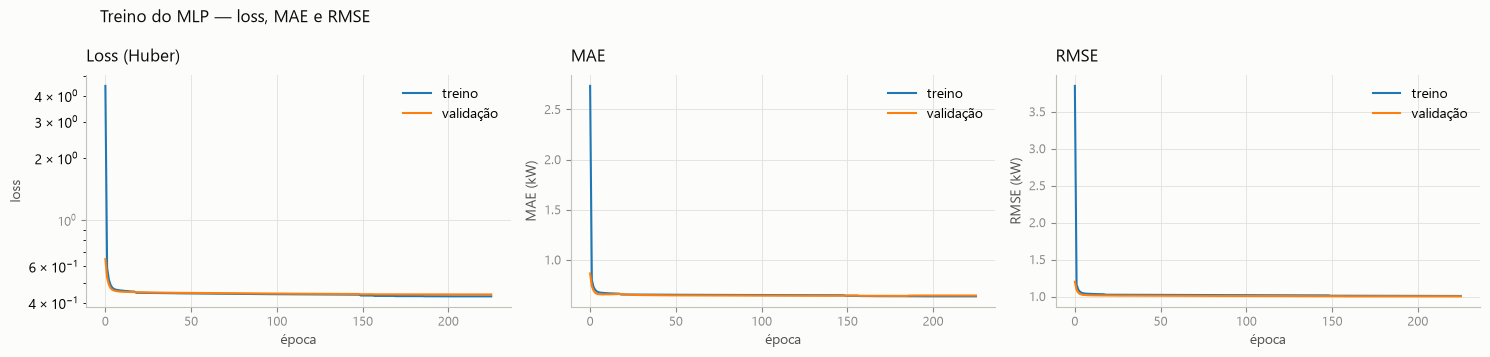

In [12]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
for eixo, chave, titulo, ylabel in (
    (eixos[0], "loss", "Loss (Huber)", "loss"),
    (eixos[1], "mae", "MAE", "MAE (kW)"),
    (eixos[2], "rmse", "RMSE", "RMSE (kW)"),
):
    eixo.plot(historico.history[chave], label="treino")
    eixo.plot(historico.history[f"val_{chave}"], label="validação")
    plots.enfeitar(eixo, titulo, "época", ylabel)
    eixo.legend(frameon=False)
eixos[0].set_yscale("log")
fig.suptitle("Treino do MLP — loss, MAE e RMSE", x=0.07, ha="left",
             color=plots.TINTA)
fig.tight_layout()
plt.show()


In [13]:
# Checkpoint Keras: salva o modelo treinado e recarrega antes do teste.
SAIDA = paths.EXPORT_MLP
SAIDA.mkdir(parents=True, exist_ok=True)
caminho_modelo = SAIDA / "modelo.keras"
modelo.save(caminho_modelo)

modelo_carregado = keras.models.load_model(caminho_modelo, compile=False)
n = min(256, len(X_tes))
assert np.allclose(modelo.predict(X_tes[:n], verbose=0),
                   modelo_carregado.predict(X_tes[:n], verbose=0), atol=1e-6)
print(f"modelo salvo e recarregado: {caminho_modelo} "
      f"({caminho_modelo.stat().st_size / 1024:.1f} KB)")


modelo salvo e recarregado: C:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\modelo_exportado\modelo.keras (525.2 KB)


keras (MLP)          MAE 1.1092 kW | RMSE 1.4245 kW | R2 0.9433 | vies +1.0901 kW


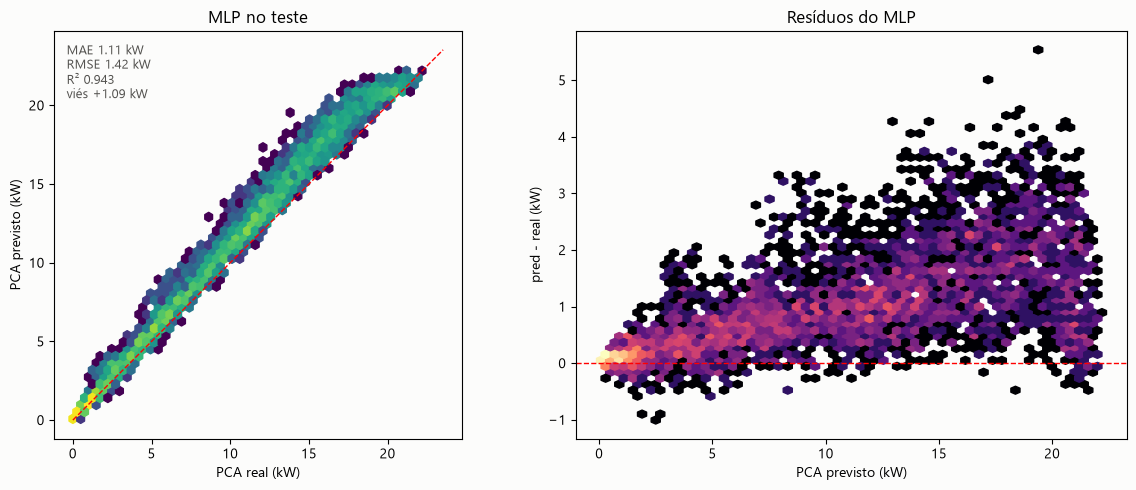

In [14]:
pred = modelo_carregado.predict(X_tes, batch_size=512, verbose=0).ravel()
resultado = metrics.evaluate("keras (MLP)", y_tes, pred)

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
plots.hexbin_real_vs_pred(eixos[0], y_tes, pred, "MLP no teste")
plots.hexbin_residuo(eixos[1], y_tes, pred, "Resíduos do MLP")
eixos[1].set_ylabel("pred - real (kW)")
texto = chr(10).join([
    f"MAE {resultado['MAE (kW)']:.2f} kW",
    f"RMSE {resultado['RMSE (kW)']:.2f} kW",
    f"R² {resultado['R2']:.3f}",
    f"viés {resultado['vies (kW)']:+.2f} kW",
])
eixos[0].text(0.03, 0.97, texto, transform=eixos[0].transAxes, va="top",
              color=plots.TINTA_2, fontsize=9, bbox=plots.HALO)
fig.tight_layout()
plt.show()
